# 05 · Does extra model complexity improve the alert queue?

The first analysis already published six course models on the June–August 2018 holdout. This follow-up adds one challenger, CatBoost, using the same 19 checkout fields, label, folds, cutoffs and budget. Three questions guide the comparison.

1. Does native handling of regions and product categories improve on regularized logistic regression?
2. How much can model differences change when the observed purchase weeks are resampled?
3. What happens to a nominal 10% alert budget when orders must be scored as they arrive?

The original choice of plain logistic regression remains the primary six-model result. The holdout had already been examined before this extension, so external or later orders would be needed to confirm a new model choice.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score
from threadpoolctl import threadpool_limits

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/checkout_features.json").is_file())
TABLES, FIGURES, PROCESSED = ROOT / "results/tables", ROOT / "results/figures", ROOT / "data/processed"
decision = json.loads((TABLES / "model_selection.json").read_text())
schema = json.loads((ROOT / "data/checkout_features.json").read_text())
features = sum(schema.values(), [])
seed = decision["seed"]
primary = decision["selected_family"]
reference = decision["regularized_logistic_comparator"]
val_start, test_start = pd.to_datetime([decision["validation_start"], decision["test_start"]])

orders = pd.read_parquet(PROCESSED / "orders.parquet").sort_values(["purchased_at", "order_id"]).reset_index(drop=True)
train = orders.loc[orders.split.eq("train") & orders.label_observed_at.lt(val_start)]
val_window = orders.loc[orders.split.eq("validation")]
valid = val_window.loc[val_window.label_observed_at.lt(test_start)]
refit = orders.loc[orders.purchased_at.lt(test_start) & orders.label_observed_at.lt(test_start)]
test = orders.loc[orders.split.eq("test")]
assert train.label_observed_at.max() < val_start and refit.label_observed_at.max() < test_start

X = orders[features].copy()
for column in schema["categorical"]:
    X[column] = X[column].fillna("__missing__").astype(str)
course_folds = pd.read_csv(TABLES / "training_cv_folds.csv", parse_dates=["score_from", "score_before"])

## Fit one categorical boosting challenger

CatBoost receives the state, category and weekday fields as categories. Rows are ordered by purchase time and then order ID. The model uses ordered boosting and keeps the supplied order when constructing categorical statistics. Each fit receives only labels available at that fold's cutoff. Numeric missing values use CatBoost's native handling.

Compare depths 4 and 6 over 180 boosting steps at learning rate 0.05. Select depth by the mean AP of the three training folds, with shallower depth winning ties. The validation and test outcomes play no role in that choice. [CatBoost paper](https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html) · [Training parameters](https://catboost.ai/docs/en/references/training-parameters/common#has_time)

In [2]:
def new_catboost(depth):
    return CatBoostClassifier(
        cat_features=schema["categorical"], loss_function="Logloss", boosting_type="Ordered",
        has_time=True, max_ctr_complexity=1, iterations=180, learning_rate=.05, depth=depth,
        l2_leaf_reg=5, thread_count=4, random_seed=seed, verbose=False, allow_writing_files=False,
    )

cv_rows = []
for depth in (4, 6):
    for fold_id, fold in enumerate(course_folds.itertuples(index=False), start=1):
        fit_part = train.loc[train.purchased_at.lt(fold.score_from) & train.label_observed_at.lt(fold.score_from)]
        score_part = train.loc[train.purchased_at.ge(fold.score_from) & train.purchased_at.lt(fold.score_before)]
        assert len(fit_part) == fold.fit_orders and len(score_part) == fold.score_orders
        model = new_catboost(depth).fit(X.loc[fit_part.index], fit_part.late)
        risk = model.predict_proba(X.loc[score_part.index])[:, 1]
        cv_rows.append({"depth": depth, "fold": fold_id, "fit_orders": len(fit_part), "score_orders": len(score_part),
                        "score_from": fold.score_from.date(), "score_before": fold.score_before.date(),
                        "ap": average_precision_score(score_part.late, risk)})
cv = pd.DataFrame(cv_rows)
mean_ap = cv.groupby("depth", sort=True).ap.mean()
depth_selected = int(mean_ap.idxmax())
cv["mean_ap"] = cv.depth.map(mean_ap)
cv["selected"] = cv.depth.eq(depth_selected)
cv.to_csv(TABLES / "catboost_cv.csv", index=False)
display(cv.pivot(index="depth", columns="fold", values="ap").assign(mean_ap=mean_ap).round(4))
print(f"Depth selected inside training: {depth_selected}.")

fold,1,2,3,mean_ap
depth,,,,
4,0.1463,0.0914,0.1847,0.1408
6,0.1428,0.0863,0.1893,0.1395


Depth selected inside training: 4.


## Score all seven models on identical orders

For validation, CatBoost is fitted on the same label-available training orders as the six course models. For test, refit at the test cutoff with all then-observed labels. Join the six saved score vectors by order ID and verify their published metrics before computing differences. AP is the non-interpolated average precision. Ranking ties are broken by order ID for budget metrics, while AP and ROC-AUC retain the tied scores.

In [3]:
val_fit = new_catboost(depth_selected).fit(X.loc[train.index], train.late)
cat_val = val_fit.predict_proba(X.loc[valid.index])[:, 1]
test_fit = new_catboost(depth_selected).fit(X.loc[refit.index], refit.late)
cat_test = test_fit.predict_proba(X.loc[test.index])[:, 1]

raw_scores = pd.read_parquet(PROCESSED / "course_test_scores.parquet").set_index("order_id")
assert raw_scores.index.is_unique and set(raw_scores.index) == set(test.order_id)
scores = raw_scores.loc[test.order_id].copy()
scores["CatBoost"] = cat_test
assert np.isfinite(scores.to_numpy()).all() and scores.ge(0).all().all() and scores.le(1).all().all()
scores.to_parquet(PROCESSED / "all_test_scores.parquet")
y = test.late.to_numpy(dtype=int)
n, positives = len(test), int(y.sum())
ids = test.order_id.to_numpy(dtype=str)
ranks = {name: np.lexsort((ids, -scores[name].to_numpy())) for name in scores}
original_test = pd.read_csv(TABLES / "test_metrics.csv", index_col="family")
original_val = pd.read_csv(TABLES / "validation_metrics.csv", index_col="family")
validation_ap = original_val.ap.to_dict()
validation_ap["CatBoost"] = average_precision_score(valid.late, cat_val)
cv_ap = pd.read_csv(TABLES / "cv_sensitivity.csv").query("selected").set_index("family").mean_ap.to_dict()
cv_ap["CatBoost"] = mean_ap[depth_selected]

summary = []
for name, ranking in ranks.items():
    k = n // 10
    caught = int(y[ranking[:k]].sum())
    summary.append({"family": name, "mean_training_cv_ap": cv_ap[name], "validation_ap": validation_ap[name],
                    "test_roc_auc": roc_auc_score(y, scores[name]), "test_ap": average_precision_score(y, scores[name]),
                    "orders": n, "late_orders": positives, "flagged": k, "caught": caught,
                    "recall_at_10pct": caught / positives, "precision_at_10pct": caught / k,
                    "lift_at_10pct": (caught / k) / (positives / n)})
comparison = pd.DataFrame(summary).set_index("family")
old = comparison.loc[original_test.index]
assert np.allclose(old[["test_ap", "test_roc_auc", "recall_at_10pct", "caught"]],
                   original_test[["ap", "roc_auc", "recall_at_10pct", "caught"]])
comparison["ap_delta_vs_regularized"] = comparison.test_ap - comparison.at[reference, "test_ap"]
comparison["recall_delta_vs_regularized"] = comparison.recall_at_10pct - comparison.at[reference, "recall_at_10pct"]
comparison.to_csv(TABLES / "all_model_comparison.csv")
display(comparison[["validation_ap", "test_roc_auc", "test_ap", "ap_delta_vs_regularized",
                    "caught", "recall_at_10pct", "precision_at_10pct"]].round(4))

,validation_ap,test_roc_auc,test_ap,ap_delta_vs_regularized,caught,recall_at_10pct,precision_at_10pct
family,,,,,,,
Logistic,0.1236,0.6418,0.0798,0.0068,122,0.1968,0.0843
Lasso logistic,0.1193,0.6074,0.0710,-0.0021,103,0.1661,0.0711
Ridge logistic,0.1208,0.6212,0.0731,0.0000,111,0.1790,0.0767
Pruned tree,0.0610,0.5794,0.0548,-0.0182,68,0.1097,0.0470
Random forest,0.0990,0.4847,0.0544,-0.0187,94,0.1516,0.0649
Gradient boosting,0.1112,0.5841,0.0570,-0.0161,87,0.1403,0.0601
CatBoost,0.0859,0.4968,0.0503,-0.0228,89,0.1435,0.0615


## Paired uncertainty across purchase weeks

Partition test purchases into consecutive seven-day blocks from the test start. Draw the same blocks with replacement for every fitted model. In each replicate recalculate AP and re-rank the quota for its new number of orders. A block drawn twice contributes two copies of every order in it.

The 2.5th and 97.5th percentiles describe variability across the observed weeks with the models fixed. This window contains only ten blocks. These intervals do not capture retraining variability or uncertainty about future regimes.

In [4]:
week = (test.purchased_at.dt.normalize() - test_start).dt.days.to_numpy() // 7
unique_weeks, block_id = np.unique(week, return_inverse=True)
n_weeks = len(unique_weeks)
rng = np.random.default_rng(seed)
block_draws = rng.multinomial(n_weeks, np.full(n_weeks, 1 / n_weeks), size=1000)

def recall_of_weighted_top_decile(ranked_labels, copies):
    budget = int(copies.sum()) // 10
    copies_before = np.cumsum(copies) - copies
    used = np.minimum(copies, np.maximum(budget - copies_before, 0))
    return (used @ ranked_labels) / (copies @ ranked_labels)

boot_ap, boot_recall = {}, {}
for name, ranking in ranks.items():
    # Pre-sort once. All equal scores share one PR threshold, including a pruned tree's tied leaves.
    ranked_y = y[ranking]
    p = scores[name].to_numpy()[ranking]
    starts = np.r_[0, np.flatnonzero(p[1:] != p[:-1]) + 1]
    ap_values, recall_values = [], []
    for block_copies in block_draws:
        copies = block_copies[block_id[ranking]]
        late_by_score = np.add.reduceat(copies * ranked_y, starts)
        n_by_score = np.add.reduceat(copies, starts)
        cum_n = n_by_score.cumsum()
        precision = np.divide(late_by_score.cumsum(), cum_n, out=np.zeros_like(cum_n, dtype=float), where=cum_n > 0)
        ap_values.append((precision @ late_by_score) / late_by_score.sum())
        recall_values.append(recall_of_weighted_top_decile(ranked_y, copies))
    boot_ap[name], boot_recall[name] = np.asarray(ap_values), np.asarray(recall_values)
    # Independently check a weighted replicate with scikit-learn, including score ties.
    weights = block_draws[0][block_id]
    assert np.isclose(boot_ap[name][0], average_precision_score(y, scores[name], sample_weight=weights))
    assert np.isclose(boot_recall[name][0], np.repeat(ranked_y, weights[ranking])[:int(weights.sum()) // 10].sum()
                      / (weights @ y))

intervals = []
for name in scores:
    record = {"family": name, "reference": reference, "weekly_blocks": n_weeks, "replicates": len(block_draws)}
    for metric, draws, estimate in [("ap", boot_ap, "test_ap"), ("recall", boot_recall, "recall_at_10pct")]:
        record[metric] = comparison.at[name, estimate]
        record[metric + "_low"], record[metric + "_high"] = np.quantile(draws[name], [.025, .975])
        record[metric + "_delta"] = comparison.at[name, estimate] - comparison.at[reference, estimate]
        record[metric + "_delta_low"], record[metric + "_delta_high"] = np.quantile(
            draws[name] - draws[reference], [.025, .975])
    intervals.append(record)
intervals = pd.DataFrame(intervals).set_index("family")
intervals.to_csv(TABLES / "paired_weekly_intervals.csv")
display(intervals[["ap_delta", "ap_delta_low", "ap_delta_high", "recall_delta",
                   "recall_delta_low", "recall_delta_high"]].round(4))

,ap_delta,ap_delta_low,ap_delta_high,recall_delta,recall_delta_low,recall_delta_high
family,,,,,,
Logistic,0.0068,-0.0003,0.0383,0.0177,-0.0037,0.0517
Lasso logistic,-0.0021,-0.0123,0.0020,-0.0129,-0.0953,0.0099
Ridge logistic,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Pruned tree,-0.0182,-0.0352,0.0008,-0.0694,-0.1296,-0.0139
Random forest,-0.0187,-0.0430,0.0498,-0.0274,-0.0831,0.0368
Gradient boosting,-0.0161,-0.0322,0.0099,-0.0387,-0.0918,0.0278
CatBoost,-0.0228,-0.0320,-0.0084,-0.0355,-0.0972,-0.0123


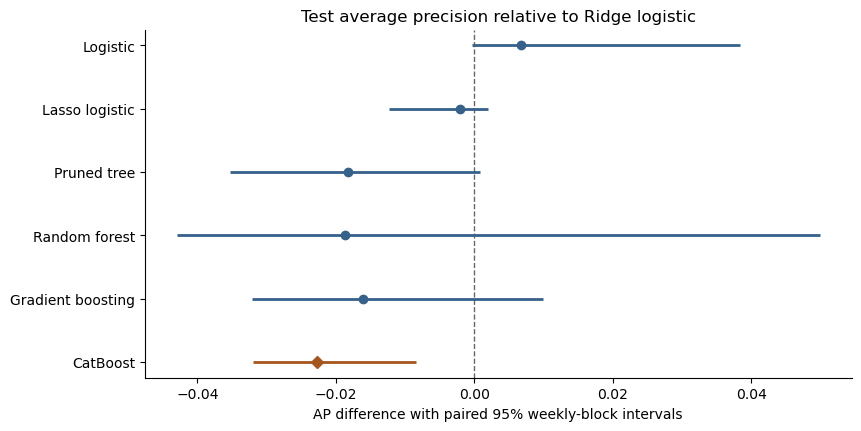

In [5]:
plot = intervals.drop(index=reference).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.2), constrained_layout=True)
ax.axvline(0, color="#666", lw=1, ls="--")
for pos, (name, row) in enumerate(plot.iterrows()):
    color = "#a6551d" if name == "CatBoost" else "#35618a"
    ax.hlines(pos, row.ap_delta_low, row.ap_delta_high, color=color, lw=2)
    ax.plot(row.ap_delta, pos, "D" if name == "CatBoost" else "o", color=color)
ax.set_yticks(range(len(plot)), plot.index)
ax.set(title=f"Test average precision relative to {reference}",
       xlabel="AP difference with paired 95% weekly-block intervals")
ax.spines[["right", "top"]].set_visible(False)
fig.savefig(FIGURES / "test_paired_ap_differences.png", dpi=140)
plt.show()

Plain logistic regression scored 0.0798 test AP and Ridge scored 0.0731. Their paired AP difference was +0.0068, with a 95% weekly-block interval of −0.0003 to +0.0383. CatBoost scored 0.0503 AP and caught 89 of 620 delays at the 10% budget, compared with 111 for Ridge. Its AP difference from Ridge was −0.0228 (−0.0320 to −0.0084). The original logistic model remains the primary choice.

## How many delays can different budgets capture?

Rank the same held-out orders once per model. A budget of b% flags exactly floor(N × b / 100) orders over the full test window. The curve compares the original primary model, the regularized comparator and CatBoost. The CSV contains all seven models and exact confusion counts for each budget.

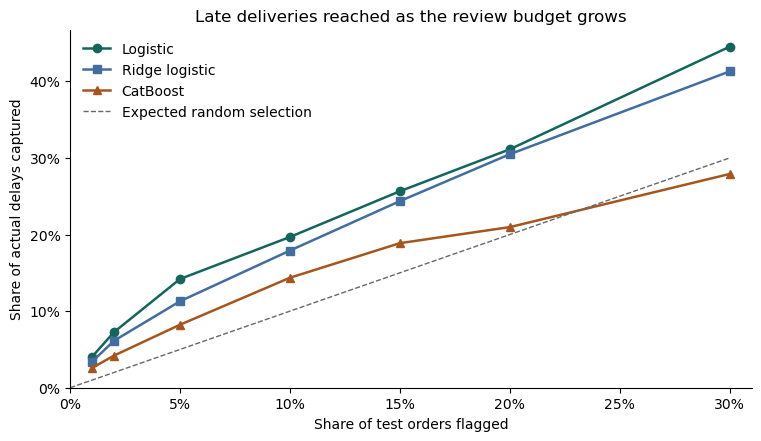

In [6]:
budgets = [1, 2, 5, 10, 15, 20, 30]
rows = []
for name, ranking in ranks.items():
    for pct in budgets:
        k = n * pct // 100
        caught = int(y[ranking[:k]].sum())
        rows.append({"family": name, "budget_pct": pct, "orders": n, "late_orders": positives,
                     "flagged": k, "caught": caught, "false_alerts": k - caught, "missed": positives - caught,
                     "alert_share": k / n, "recall": caught / positives, "precision": caught / k,
                     "lift": (caught / k) / (positives / n)})
budget_table = pd.DataFrame(rows)
budget_table.to_csv(TABLES / "test_screening_budgets.csv", index=False)
at_ten = budget_table.query("budget_pct == 10").set_index("family")
assert at_ten.caught.equals(comparison.caught)
fig, ax = plt.subplots(figsize=(7.5, 4.3), constrained_layout=True)
for name, color, marker in [(primary, "#14665d", "o"), (reference, "#426d9f", "s"), ("CatBoost", "#a6551d", "^")]:
    curve = budget_table.loc[budget_table.family.eq(name)]
    ax.plot(curve.alert_share, curve.recall, marker=marker, label=name, color=color, lw=1.8)
ax.plot([0, .30], [0, .30], "--", color="#686868", lw=1, label="Expected random selection")
ax.set(title="Late deliveries reached as the review budget grows",
       xlabel="Share of test orders flagged", ylabel="Share of actual delays captured", xlim=(0, .31), ylim=(0, None))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(frameon=False)
ax.spines[["right", "top"]].set_visible(False)
fig.savefig(FIGURES / "test_capture_by_budget.png", dpi=140)
plt.show()

The primary model caught 88, 122 and 193 of the 620 delays at budgets of 5%, 10% and 20%. Expanding review from 10% to 20% took 1,449 additional checks to reach 71 more delays. Precision fell from 8.4% to 6.7%.

## Compare retrospective ranking with an at-checkout threshold

The window-wide ranking requires all future scores in the test period. End-of-day ranking needs the rest of that day's orders. An immediately usable rule can instead freeze a numerical cutoff before test begins.

Use the **same training-only primary model** to score every validation purchase and every test purchase. Calibrate its cutoff on the highest 10% of validation scores using features only. Keep that fitted model and cutoff fixed to avoid a change in score scale. Compare all three policies on the same test orders. This policy experiment has a different fit date from the main refitted model comparison.

In [7]:
frozen = joblib.load(PROCESSED / "validation_models.joblib")["selected"]
with threadpool_limits(limits=2):
    calibration = pd.DataFrame({"order_id": val_window.order_id,
                                "risk": frozen.predict_proba(val_window[features])[:, 1]})
    policy = test[["order_id", "purchased_at", "late"]].copy()
    policy["risk"] = frozen.predict_proba(test[features])[:, 1]
calibration = calibration.sort_values(["risk", "order_id"], ascending=[False, True])
cut_row = calibration.iloc[len(calibration) // 10 - 1]

def passes_cutoff(frame):
    return frame.risk.gt(cut_row.risk) | (frame.risk.eq(cut_row.risk) & frame.order_id.le(cut_row.order_id))

assert passes_cutoff(calibration).sum() == len(calibration) // 10
policy = policy.sort_values(["risk", "order_id"], ascending=[False, True])
purchase_day = policy.purchased_at.dt.normalize()
daily_groups = policy.groupby(purchase_day)
masks = {
    "Whole-window ranking": np.arange(len(policy)) < len(policy) // 10,
    "End-of-day ranking": daily_groups.cumcount() < daily_groups.order_id.transform("size") // 10,
    "Frozen validation cutoff": passes_cutoff(policy),
}
policy_rows = []
for label, flagged in masks.items():
    alerts = int(np.sum(flagged))
    caught = int(policy.loc[flagged, "late"].sum())
    policy_rows.append({"policy": label, "family": primary, "fit_before": val_start.date(), "orders": len(policy),
                        "late_orders": positives, "flagged": alerts, "alert_share": alerts / n, "caught": caught,
                        "false_alerts": alerts - caught, "missed": positives - caught, "recall": caught / positives,
                        "precision": caught / alerts if alerts else np.nan,
                        "frozen_cutoff": float(cut_row.risk) if label == "Frozen validation cutoff" else np.nan})
policies = pd.DataFrame(policy_rows).set_index("policy")
assert policies.iloc[1].flagged == (daily_groups.size() // 10).sum()
assert (policies.caught + policies.missed == positives).all()
policies.to_csv(TABLES / "test_screening_policies.csv")
display(policies[["flagged", "alert_share", "caught", "missed", "recall", "precision"]].style.format(
    {"alert_share": "{:.1%}", "recall": "{:.1%}", "precision": "{:.1%}"}))
print(f"Cutoff {cut_row.risk:.5f} calibrated on {len(calibration):,} validation purchases.")

,flagged,alert_share,caught,missed,recall,precision
policy,,,,,,
Whole-window ranking,1448,10.0%,110,510,17.7%,7.6%
End-of-day ranking,1414,9.8%,96,524,15.5%,6.8%
Frozen validation cutoff,1910,13.2%,130,490,21.0%,6.8%


Cutoff 0.08078 calibrated on 14,606 validation purchases.


With the earlier fit held fixed, full-period ranking reached 110 delays and daily ranking reached 96. The frozen cutoff was available immediately and reached 130, while alerting on 1,910 orders (13.2%). A validation target of 10% therefore did not enforce a 10% review capacity in the later period.